## Tarea 4 - Física Computacional II
**Nombre completo:** [Isidora Araya]
**RUT:** [22.502.569-K]

# Parte 1

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=996)

#esto para definir las constantes físicas
sigmasb = 5.670374419e-8
Ls = 3.828e26
Rs = 6.957e8
pcm = 3.0857e16

In [ ]:
n = np.arange(1, 101) #Creamos un arreglo con los identificadores de las estrellas (del 1 al 100)
r = rng.uniform(0.5, 5, 100) #Radio estelar: entre 0.5 y 5 Radios Solares
d = rng.uniform(50, 500, 100) #Distancia: entre 50 y 500 pársecs (pc)
T = rng.uniform(3000, 10000, 100) #Temperatura efectiva: entre 3000 y 10000 Kelvin (K)

df = pd.DataFrame({
    'Estrellas': n,
    'Radios': r,
    'Distancias': d,
    'Temperaturas': T
})

#El diccionario es para juntar las 4 listas anteriores

print("Primeras 10 filas")
display(df.head(10))
print("Estadísticas descriptivas")
display(df.describe())

Primeras 10 filas
    Estrellas    Radios  Distancias  Temperaturas
0           1  0.582849  168.081053   6400.817687
1           2  1.630268  164.240823   8795.678789
2           3  4.628313  108.254148   4616.729677
3           4  2.403137  272.661968   6840.181213
4           5  2.603034  428.679042   7487.087429
..        ...       ...         ...           ...
95         96  1.600970  237.879343   5638.860461
96         97  1.810550  233.143661   4588.820963
97         98  4.636496  458.062055   3727.871936
98         99  2.395536  224.133394   5557.746696
99        100  0.663374  303.860977   3970.144274

[100 rows x 4 columns]


# Parte 2

In [56]:
def calcularSI(rsun, dpc, TK):
    """CALCULAR LUMINOSIDAD Y FLUJO
    Calcula la luminosidad de una estrella mediante la ley de Stefan-Boltzmann
    y el flujo observado a una distancia dada.

    Parámetros
    ----------
    rsun : float
        Radio estelar en radios solares (R_sun).
    dpc : float
        Distancia a la estrella en pársecs (pc).
    TK : float
        Temperatura efectiva de la estrella en Kelvin (K).

    Salida
    ------
    Lsol : float
        Luminosidad de la estrella expresada en luminosidades solares (L_sun).
    F : float
        Flujo observado de la estrella en W/m^2.
    """
    
    #Convertimos el radio a metros y la distancia de pc a metros
    rm = rsun * Rs
    dm = dpc * pcm
    
    # Calculamos la Luminosidad en Watts usando la Ley de Stefan-Boltzmann
    Lwatts = 4 * np.pi * (rm**2) * sigmasb * (TK**4)
    
    # 3. Convertimos la Luminosidad a Lsol
    Lsol = Lwatts / Ls
    
    # 4. Calculamos el Flujo
    F = Lwatts / (4 * np.pi * (dm**2))
    
    return Lsol, F

#Creamos listas vacías donde guardaremos los resultados
Luminosidades = []
Flujos = []

#Recorremos las 100 estrellas del DataFrame
for i in range(100):
    rval = df.loc[i, 'Radios']
    dval = df.loc[i, 'Distancias']
    tval = df.loc[i, 'Temperaturas']
    
    #Llamamos a la función y guardamos los resultados
    Lval, Fval = calcularSI(rval, dval, tval)
    Luminosidades.append(Lval)
    Flujos.append(Fval)

#Incorporamos las listas como nuevas columnas en el DataFrame
df['LuminosidadLsun'] = Luminosidades
df['Flujo'] = Flujos

#Buscamos los valores máximos y mínimos
maxL = df['LuminosidadLsun'].max()
minL = df['LuminosidadLsun'].min()
maxF = df['Flujo'].max()
minF = df['Flujo'].min()

#Esto se usa para filtrar y encontrar las filas exactas
estrellamaxL = df[df['LuminosidadLsun'] == maxL]
estrellaminL = df[df['LuminosidadLsun'] == minL]
estrellamaxF = df[df['Flujo'] == maxF]
estrellaminF = df[df['Flujo'] == minF]

print("Estrella con mayor Luminosidad")
print()
print(estrellamaxL)
print()
print("Estrella con menor Luminosidad")
print()
print(estrellaminL)
print()
print("Estrella con mayor Flujo")
print()
print(estrellamaxF)
print()
print("Estrella con menor Flujo")
print()
print(estrellaminF)

Estrella con mayor Luminosidad

    Estrellas    Radios  Distancias  Temperaturas  LuminosidadLsun  \
41         42  4.031957  366.952784   9709.533672       130.172421   

           Flujo  
41  3.092810e-11  

Estrella con menor Luminosidad

    Estrellas    Radios  Distancias  Temperaturas  LuminosidadLsun  \
99        100  0.663374  303.860977   3970.144274           0.0985   

           Flujo  
99  3.413029e-14  

Estrella con mayor Flujo

    Estrellas    Radios  Distancias  Temperaturas  LuminosidadLsun  \
89         90  4.995658   72.888292    8314.41428       107.449819   

           Flujo  
89  6.470604e-10  

Estrella con menor Flujo

    Estrellas    Radios  Distancias  Temperaturas  LuminosidadLsun  \
99        100  0.663374  303.860977   3970.144274           0.0985   

           Flujo  
99  3.413029e-14  


In [57]:
Flim = 2e-10 

#Aqui guardaremos las clasificaciones
clasificaciones = []

#Recorremos las 100 estrellas
for i in range(100):
    fval = df.loc[i, 'Flujo']
    
    if fval >= Flim:
        clasificaciones.append('Detectada')
    else:
        clasificaciones.append('No detectada')

#Incorporamos la lista como una nueva columna en el DataFrame
df['Clasificacion'] = clasificaciones

# Contamos cuántas estrellas hay
conteo = df['Clasificacion'].value_counts()
porcentaje = df['Clasificacion'].value_counts(normalize=True) * 100


tabla_conteo = pd.DataFrame({
    'Cantidad de Estrellas': conteo,
    'Porcentaje (%)': porcentaje
})

print("Tabla 1: Resumen de Clasificación")
print(tabla_conteo)

# Esto se usa para calcular los promedios de las propiedades)
promedios = df.groupby('Clasificacion')[['Flujo', 'Distancias', 'Temperaturas']].mean()

# Esto se usa para renombrar las columnas para que se vean más bonitas en la tabla)
promedios.columns = ['Flujo Promedio (W/m^2)', 'Distancia Promedio (pc)', 'Temperatura Promedio (K)']

print("Promedios por Categoría")
print(promedios)

Tabla 1: Resumen de Clasificación
               Cantidad de Estrellas  Porcentaje (%)
Clasificacion                                       
No detectada                      97            97.0
Detectada                          3             3.0
Promedios por Categoría
               Flujo Promedio (W/m^2)  Distancia Promedio (pc)  \
Clasificacion                                                    
Detectada                4.604408e-10                81.103680   
No detectada             2.027229e-11               257.383977   

               Temperatura Promedio (K)  
Clasificacion                            
Detectada                   8580.627643  
No detectada                6530.024604  


<>:13: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
<>:27: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
<>:70: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
<>:13: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
<>:27: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
<>:70: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
C:\Users\isido\AppData\Local\Temp\ipykernel_4328\636226010.py:13: SyntaxWarn

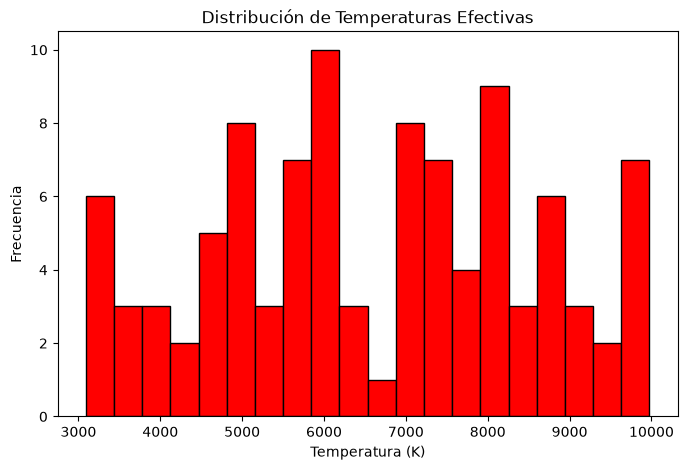

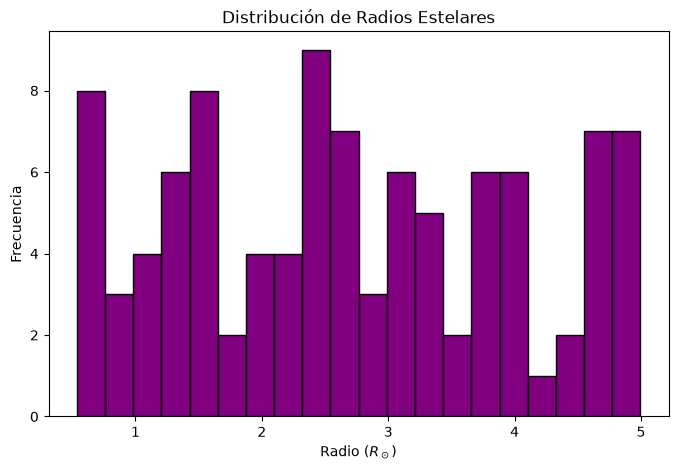

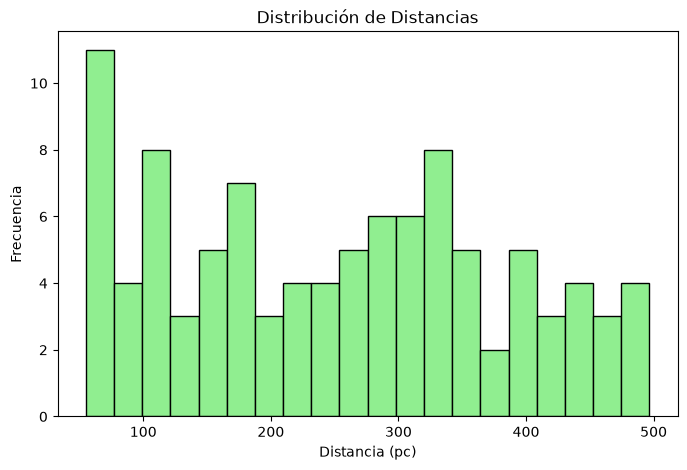

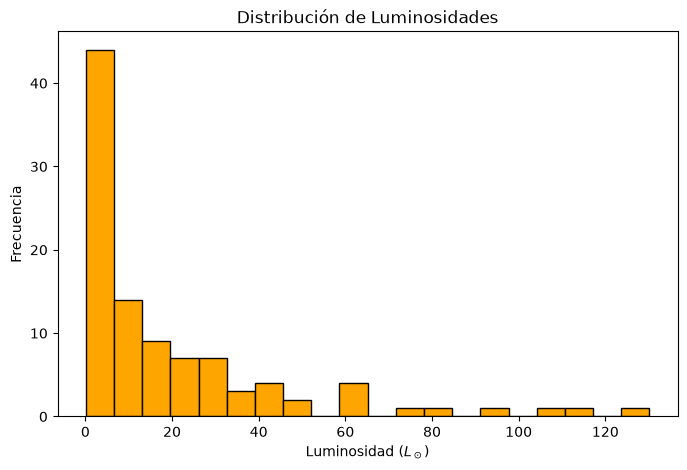

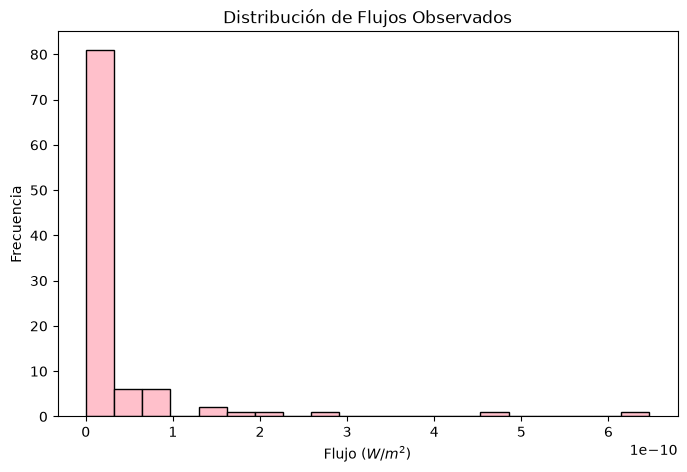

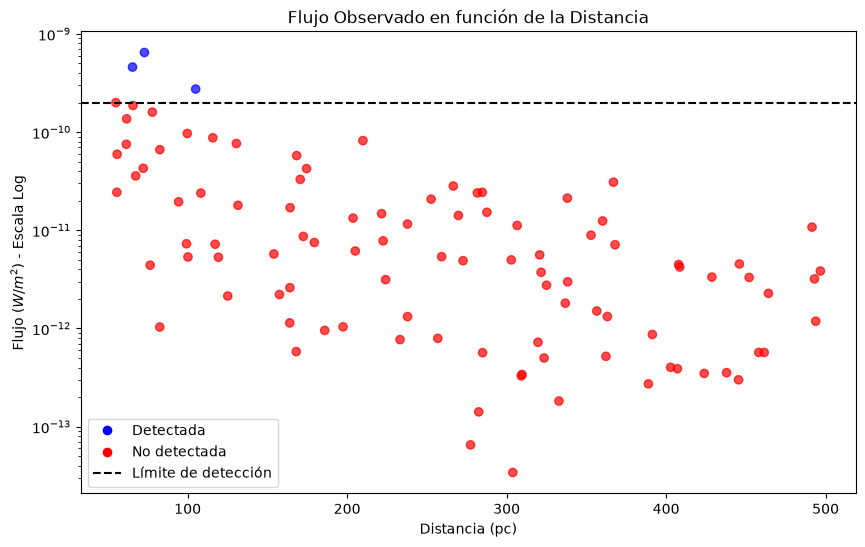

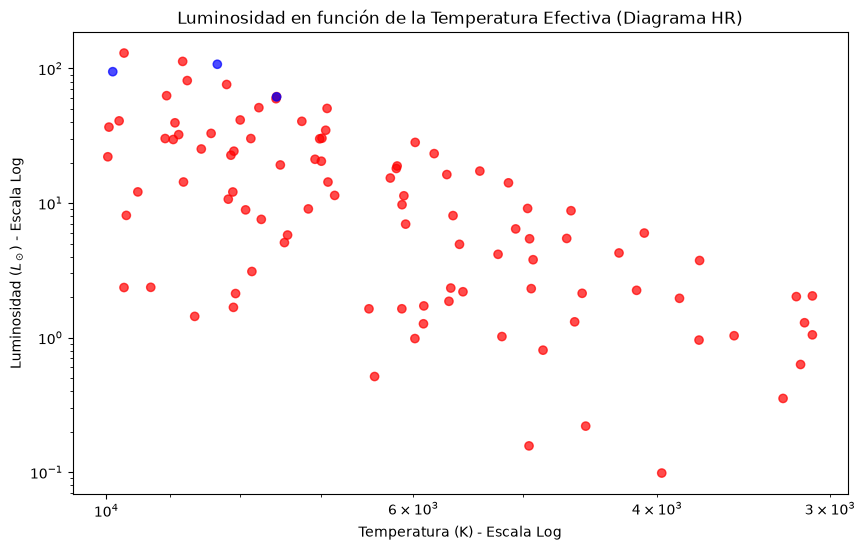

In [58]:
#Configuraramos un tamaño de figura estándar para todos los gráficos)
plt.figure(figsize=(8, 5))

plt.hist(df['Temperaturas'], bins=20, color='red', edgecolor='black')
plt.title('Distribución de Temperaturas Efectivas')
plt.xlabel('Temperatura (K)')
plt.ylabel('Frecuencia')
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(df['Radios'], bins=20, color='purple', edgecolor='black')
plt.title('Distribución de Radios Estelares')
plt.xlabel('Radio ($R_\odot$)')
plt.ylabel('Frecuencia')
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(df['Distancias'], bins=20, color='lightgreen', edgecolor='black')
plt.title('Distribución de Distancias')
plt.xlabel('Distancia (pc)')
plt.ylabel('Frecuencia')
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(df['LuminosidadLsun'], bins=20, color='orange', edgecolor='black')
plt.title('Distribución de Luminosidades')
plt.xlabel('Luminosidad ($L_\odot$)')
plt.ylabel('Frecuencia')
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(df['Flujo'], bins=20, color='pink', edgecolor='black')
plt.title('Distribución de Flujos Observados')
plt.xlabel('Flujo ($W/m^2$)')
plt.ylabel('Frecuencia')
plt.show()

plt.figure(figsize=(10, 6))

colores = {'Detectada': 'blue', 'No detectada': 'red'}
colores_puntos = df['Clasificacion'].map(colores)

plt.scatter(df['Distancias'], df['Flujo'], c=colores_puntos, alpha=0.7, label='Estrellas')

plt.axhline(y=Flim, color='black', linestyle='--', label=f'Límite de detección ({Flim} $W/m^2$)')

plt.yscale('log')

plt.title('Flujo Observado en función de la Distancia')
plt.xlabel('Distancia (pc)')
plt.ylabel('Flujo ($W/m^2$) - Escala Log')

from matplotlib.lines import Line2D
legend_elements = [Line2D([0], [0], marker='o', color='w', label='Detectada', markerfacecolor='blue', markersize=8),
                   Line2D([0], [0], marker='o', color='w', label='No detectada', markerfacecolor='red', markersize=8),
                   Line2D([0], [0], color='black', linestyle='--', label='Límite de detección')]
plt.legend(handles=legend_elements)
plt.show()

plt.figure(figsize=(10, 6))

plt.scatter(df['Temperaturas'], df['LuminosidadLsun'], c=colores_puntos, alpha=0.7)

plt.xscale('log')
plt.yscale('log')
plt.gca().invert_xaxis()

plt.title('Luminosidad en función de la Temperatura Efectiva (Diagrama HR)')
plt.xlabel('Temperatura (K) - Escala Log')
plt.ylabel('Luminosidad ($L_\odot$) - Escala Log')
plt.show()